# AML Alert Triage: ML Detection + LLM Case Summaries

**Goal:** rank bank accounts by money-laundering risk so investigators review the riskiest ones first, then use an LLM to draft a case summary for each alert.

**Data:** IBM *Transactions for Anti Money Laundering* (`HI-Small_Trans.csv`), ~5M synthetic transactions with laundering labels.

**Outline**
1. Data and exploratory analysis
2. Account-level feature engineering
3. Models: rules baseline vs Isolation Forest vs XGBoost, on an out-of-time test week
4. Critical review: ablation and what drives the model
5. LLM case summaries with a hallucination (faithfulness) check
6. Conclusions and limitations

In [1]:
import json, os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb
from sklearn.ensemble import IsolationForest
from sklearn.metrics import precision_recall_curve
from sklearn.model_selection import train_test_split

sys.path.insert(0, "src")
from features import build_features
from train import rules_score, evaluate, SPLIT, SEED
import llm_summary as llm
%matplotlib inline

pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]          # fixed categorical order
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e5e0", "grid.linewidth": 0.6, "axes.edgecolor": "#8a8984",
                     "axes.titlesize": 11, "axes.titleweight": "bold", "figure.dpi": 110})

## 1. Data and exploratory analysis

`src/prepare_data.py` loads the raw CSV, converts all amounts to USD (rates estimated from cross-currency transactions) and keeps Sep 1-10. After Sep 10 there are only a few hundred transactions a day and most are laundering, a tail artifact of the simulator.

In [2]:
if not os.path.exists("data/transactions.parquet"):
    !{sys.executable} src/prepare_data.py data/HI-Small_Trans.csv.gz
tx = pd.read_parquet("data/transactions.parquet")
print(f"{len(tx):,} transactions | {tx.ts.min():%b %d} to {tx.ts.max():%b %d} | laundering rate {tx.is_laundering.mean():.3%}")
tx[["ts", "from_id", "to_id", "amt_paid", "pay_cur", "amt_usd", "pay_format", "is_laundering"]].head()

5,077,237 transactions | Sep 01 to Sep 10 | laundering rate 0.089%


,ts,from_id,to_id,amt_paid,pay_cur,amt_usd,pay_format,is_laundering
0,2022-09-01 00:20:00,010_8000EBD30,010_8000EBD30,"3,697.340",US Dollar,"3,697.340",Reinvestment,0
1,2022-09-01 00:20:00,03208_8000F4580,001_8000F5340,0.010,US Dollar,0.010,Cheque,0
2,2022-09-01 00:00:00,03209_8000F4670,03209_8000F4670,"14,675.570",US Dollar,"14,675.570",Reinvestment,0
3,2022-09-01 00:02:00,012_8000F5030,012_8000F5030,"2,806.970",US Dollar,"2,806.970",Reinvestment,0
4,2022-09-01 00:06:00,010_8000F5200,010_8000F5200,"36,682.970",US Dollar,"36,682.970",Reinvestment,0


**How rare is laundering, and which channels does it use?** Only about 1 in 1,100 transactions is laundering, so accuracy is meaningless here: predicting "clean" for everything is 99.9% accurate.

In [3]:
by_fmt = (tx.groupby("pay_format").is_laundering.agg(transactions="size", laundering="sum", rate="mean")
            .sort_values("rate", ascending=False))
by_fmt["share_of_all_laundering"] = by_fmt.laundering / by_fmt.laundering.sum()
by_fmt

,transactions,laundering,rate,share_of_all_laundering
pay_format,,,,
ACH,599689,3828,0.006,0.847
Bitcoin,146091,56,0.000,0.012
Cash,490891,108,0.000,0.024
Cheque,1864331,324,0.000,0.072
Credit Card,1323324,206,0.000,0.046
Reinvestment,481056,0,0.000,0.000
Wire,171855,0,0.000,0.000


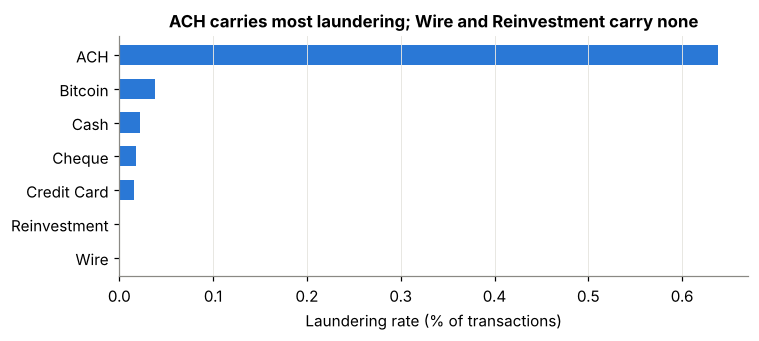

In [4]:
fig, ax = plt.subplots(figsize=(7, 3.2))
(by_fmt.rate * 100).sort_values().plot.barh(ax=ax, color=COLORS[0], width=0.6)
ax.set_xlabel("Laundering rate (% of transactions)"); ax.set_ylabel("")
ax.set_title("ACH carries most laundering; Wire and Reinvestment carry none")
ax.grid(axis="y", visible=False); plt.tight_layout(); plt.show()

ACH is the main laundering channel and **no Wire transaction is ever labelled laundering**. A clean split like this is a sign of how the simulator was built, so a model trained on it may lean on payment channel more than it could on real bank data. Section 4 tests this directly.

In [5]:
print(tx.groupby(tx.is_laundering.map({0: "Clean", 1: "Laundering"})).amt_usd.quantile([0.1, 0.5, 0.9]).unstack().round(0))

                0.100     0.500      0.900
is_laundering                             
Clean          30.000   891.000 35,451.000
Laundering    474.000 5,074.000 18,384.000


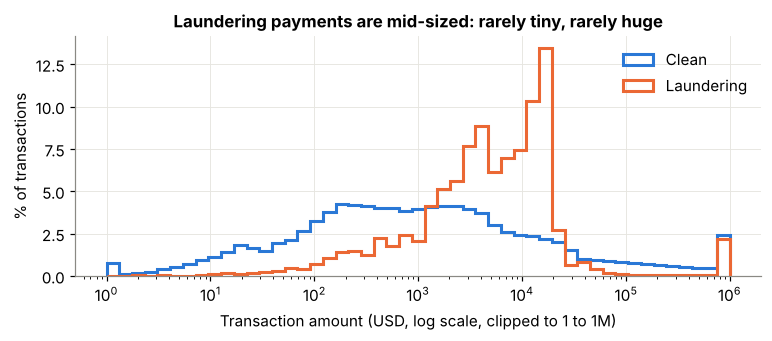

In [6]:
fig, ax = plt.subplots(figsize=(7, 3.2))
bins = np.logspace(0, 6, 50)
for lab, name, c in [(0, "Clean", COLORS[0]), (1, "Laundering", COLORS[1])]:
    amt = tx.loc[tx.is_laundering == lab, "amt_usd"].clip(1, 1e6)
    ax.hist(amt, bins=bins, weights=np.full(len(amt), 100 / len(amt)), histtype="step", lw=2, color=c, label=name)
ax.set_xscale("log"); ax.set_xlabel("Transaction amount (USD, log scale, clipped to 1 to 1M)"); ax.set_ylabel("% of transactions")
ax.set_title("Laundering payments are mid-sized: rarely tiny, rarely huge"); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

## 2. Account-level feature engineering

Investigators review **accounts**, not single payments, and laundering shows up as a pattern across several transactions. `src/features.py` aggregates each account's activity in a time window into 39 behavioural features, chosen to reflect common AML typologies:

| Feature group | Examples | Typology it reflects |
|---|---|---|
| Volume and amounts | `out_usd_sum`, `in_usd_max` | unusual value moving through the account |
| Fan-in / fan-out | `out_n_counterparties`, `in_n_banks` | smurfing, spreading funds across recipients |
| Pass-through | `pass_through` (min of in/out over max) | layering: money in, money straight out |
| Channel mix | `out_share_ach`, `in_share_cash` | channel preference |
| Currency switching | `out_n_currencies`, `out_share_cross_currency` | moving funds across currencies |
| Bursts | `out_max_txn_per_hour` | rapid movement of funds |

**Label:** an account is positive if it sent or received at least one laundering transaction in the window.

**Out-of-time split:** features and labels are built separately for **Sep 1-5 (train)** and **Sep 6-10 (test)**. This mirrors deployment, where a model trained on past weeks scores next week's activity. A random split would overstate performance.

In [7]:
X_tr, y_tr = build_features(tx[tx.ts < SPLIT])
X_te, y_te = build_features(tx[tx.ts >= SPLIT])
X_te = X_te[X_tr.columns]
pd.DataFrame({"accounts": [len(X_tr), len(X_te)], "positives": [y_tr.sum(), y_te.sum()],
              "positive_rate": [y_tr.mean(), y_te.mean()]}, index=["Train (Sep 1-5)", "Test (Sep 6-10)"])

,accounts,positives,positive_rate
Train (Sep 1-5),404273,2799,0.007
Test (Sep 6-10),372889,3357,0.009


**Do laundering accounts behave differently?** Medians of selected features in the training week:

In [8]:
cols = ["out_n_txn", "in_n_txn", "out_usd_sum", "out_n_counterparties", "out_n_currencies",
        "out_share_ach", "pass_through", "out_max_txn_per_hour"]
X_tr[cols].groupby(y_tr.map({0: "Clean", 1: "Laundering"})).median().T

label,Clean,Laundering
out_n_txn,1.000,1.000
in_n_txn,2.000,6.000
out_usd_sum,542.997,"6,473.500"
out_n_counterparties,1.000,1.000
out_n_currencies,1.000,1.000
out_share_ach,0.000,0.200
pass_through,0.000,0.009
out_max_txn_per_hour,1.000,1.000


Laundering accounts are not extreme outliers: the median one makes a single outgoing payment to a single counterparty, just like a clean account. The differences are subtler (more incoming payments, larger outgoing value, some ACH use), so no single threshold separates them. This matters for model choice below.

## 3. Models

Three ways to rank accounts for review:
- **Rules baseline:** a red-flag scorecard (heavy ACH use, pass-through > 0.8, 5+ counterparties, bursts, currency conversion), like traditional rule-based monitoring
- **Isolation Forest:** unsupervised anomaly detection, needs no labels
- **XGBoost:** supervised; `scale_pos_weight` re-weights the rare positive class, with early stopping on PR-AUC using a validation split of the training week

**Metrics:** investigators can only review a limited number of alerts, so the focus is **precision@k** (how many of the top-k alerts are real) alongside PR-AUC. ROC-AUC is shown for reference but is flattering when positives are this rare.

In [9]:
scores = {"Rules baseline": rules_score(X_te)}

iso = IsolationForest(n_estimators=200, max_samples=50_000, random_state=SEED, n_jobs=-1)
iso.fit(np.log1p(X_tr.clip(lower=0)))
scores["Isolation Forest"] = pd.Series(-iso.score_samples(np.log1p(X_te.clip(lower=0))), index=X_te.index)

X_fit, X_val, y_fit, y_val = train_test_split(X_tr, y_tr, test_size=0.2, stratify=y_tr, random_state=SEED)
params = dict(n_estimators=1000, learning_rate=0.05, max_depth=6, subsample=0.8, colsample_bytree=0.8,
              scale_pos_weight=(1 - y_fit.mean()) / y_fit.mean(), eval_metric="aucpr",
              early_stopping_rounds=50, random_state=SEED, n_jobs=-1)
model = xgb.XGBClassifier(**params).fit(X_fit, y_fit, eval_set=[(X_val, y_val)], verbose=False)
scores["XGBoost"] = pd.Series(model.predict_proba(X_te)[:, 1], index=X_te.index)
print("XGBoost best iteration:", model.best_iteration)

XGBoost best iteration: 174


## 4. Critical review: does the model just learn the simulator's shortcuts?

Section 1 showed laundering is tied to ACH and no Wire transfer is ever laundering. To check how much the model depends on that, re-train XGBoost **without any payment-channel or currency features**.

In [10]:
drop = [c for c in X_tr.columns if "n_currencies" in c or
        ("share_" in c and c.split("share_")[1] in {"ach", "cash", "cheque", "credit_card", "bitcoin", "wire", "cross_currency"})]
ablation = xgb.XGBClassifier(**params).fit(X_fit.drop(columns=drop), y_fit,
                                           eval_set=[(X_val.drop(columns=drop), y_val)], verbose=False)
scores["XGBoost (no channel/currency)"] = pd.Series(ablation.predict_proba(X_te.drop(columns=drop))[:, 1], index=X_te.index)
print(f"Dropped {len(drop)} features: {drop}")

Dropped 16 features: ['out_n_currencies', 'out_share_cross_currency', 'out_share_ach', 'out_share_cash', 'out_share_cheque', 'out_share_credit_card', 'out_share_bitcoin', 'out_share_wire', 'in_n_currencies', 'in_share_cross_currency', 'in_share_ach', 'in_share_cash', 'in_share_cheque', 'in_share_credit_card', 'in_share_bitcoin', 'in_share_wire']


### Results on the test week

In [11]:
results = pd.DataFrame({name: evaluate(y_te, s) for name, s in scores.items()}).T
results[["pr_auc", "roc_auc", "precision@100", "precision@500", "precision@1000", "recall@1000"]]

,pr_auc,roc_auc,precision@100,precision@500,precision@1000,recall@1000
Rules baseline,0.036,0.745,0.230,0.100,0.074,0.022
Isolation Forest,0.025,0.690,0.240,0.120,0.075,0.022
XGBoost,0.211,0.904,0.980,0.726,0.447,0.133
XGBoost (no channel/currency),0.103,0.847,0.880,0.338,0.209,0.062


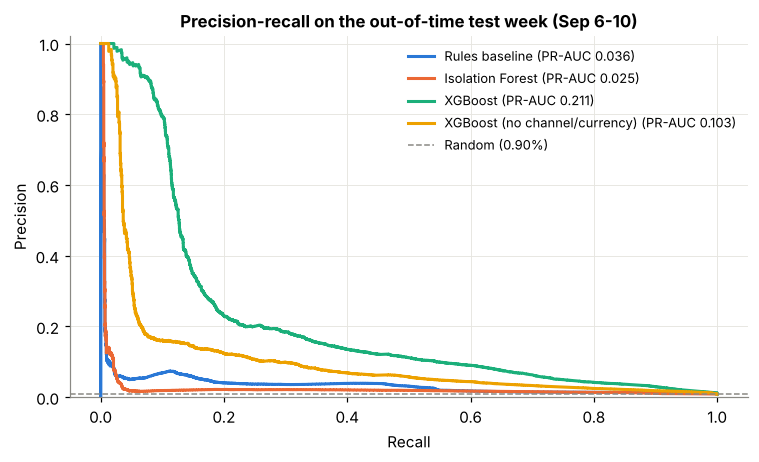

In [12]:
fig, ax = plt.subplots(figsize=(7, 4.3))
for (name, s), c in zip(scores.items(), COLORS):
    p, r, _ = precision_recall_curve(y_te, s)
    ax.plot(r, p, lw=2, color=c, label=f"{name} (PR-AUC {results.loc[name, 'pr_auc']:.3f})")
ax.axhline(y_te.mean(), color="#8a8984", ls="--", lw=1, label=f"Random ({y_te.mean():.2%})")
ax.set_xlabel("Recall"); ax.set_ylabel("Precision"); ax.set_ylim(0, 1.02)
ax.set_title("Precision-recall on the out-of-time test week (Sep 6-10)")
ax.legend(frameon=False, fontsize=8.5); plt.tight_layout(); plt.show()

In [13]:
base = y_te.mean()
p500 = results.loc["XGBoost", "precision@500"]
print(f"Top 500 alerts: XGBoost precision {p500:.1%} vs base rate {base:.2%} -> {p500 / base:.0f}x random, "
      f"{p500 / results.loc['Rules baseline', 'precision@500']:.1f}x the rules baseline")

Top 500 alerts: XGBoost precision 72.6% vs base rate 0.90% -> 81x random, 7.3x the rules baseline


**Reading the results**
- **XGBoost** is by far the best ranker. In the top 500 alerts most accounts are real laundering cases, against a base rate under 1%.
- **Isolation Forest barely beats random.** Laundering accounts here are small and ordinary-looking (section 2), so an "unusual" detector does not find them. *Unusual is not the same as suspicious*; unsupervised methods are better used to surface new patterns than as the main detector.
- **The ablation halves PR-AUC.** Much of XGBoost's edge comes from channel and currency signals that the simulator makes unusually clean. On real data, expect lower numbers; behavioural features alone still beat the rules baseline clearly.

### What drives the model
XGBoost can return each feature's contribution to each prediction (`pred_contribs=True`, the same idea as TreeSHAP). Averaged over the test week:

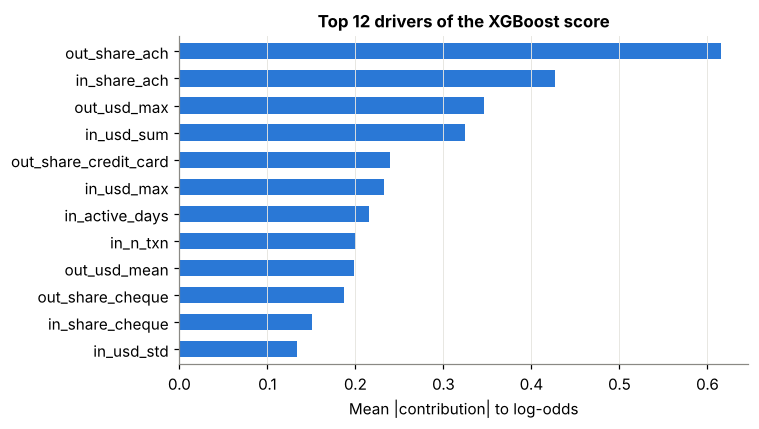

In [14]:
contrib = pd.DataFrame(model.get_booster().predict(xgb.DMatrix(X_te), pred_contribs=True)[:, :-1],
                       index=X_te.index, columns=X_te.columns)
imp = contrib.abs().mean().sort_values().tail(12)
fig, ax = plt.subplots(figsize=(7, 4))
imp.plot.barh(ax=ax, color=COLORS[0], width=0.6)
ax.set_xlabel("Mean |contribution| to log-odds"); ax.set_title("Top 12 drivers of the XGBoost score")
ax.grid(axis="y", visible=False); plt.tight_layout(); plt.show()

### The alert queue: top 10 accounts in the test week

In [15]:
top = scores["XGBoost"].sort_values(ascending=False).head(50)
queue = pd.DataFrame({
    "rank": range(1, len(top) + 1), "account": top.index, "risk_score": top.values.round(4),
    "label": y_te[top.index].values,
    "top_drivers": [json.dumps({f: round(float(X_te.at[a, f]), 4)
                                for f in contrib.loc[a].sort_values(ascending=False).head(5).index}) for a in top.index],
})
queue.to_csv("outputs/alert_queue.csv", index=False); X_te.loc[top.index].to_csv("outputs/alert_features.csv")
queue.head(10)

,rank,account,risk_score,label,top_drivers
0,1,0225215_8098DA930,0.996,1,"{""out_n_currencies"": 2.0, ""out_share_ach"": 1.0..."
1,2,00908_80419CF40,0.996,1,"{""out_n_currencies"": 2.0, ""out_share_ach"": 1.0..."
2,3,0116904_8064A8D40,0.996,1,"{""out_n_currencies"": 2.0, ""out_share_ach"": 1.0..."
3,4,012_8010D4440,0.996,1,"{""out_n_currencies"": 4.0, ""out_share_ach"": 1.0..."
4,5,001665_800F24BE0,0.995,1,"{""out_n_currencies"": 2.0, ""out_share_ach"": 1.0..."
5,6,0071_804AD1FB0,0.995,1,"{""out_n_currencies"": 2.0, ""out_share_ach"": 1.0..."
6,7,019477_80750D550,0.995,1,"{""out_n_currencies"": 2.0, ""out_share_ach"": 1.0..."
7,8,0215841_809DCF810,0.995,1,"{""out_n_currencies"": 2.0, ""out_share_ach"": 1.0..."
8,9,0139342_80EB1E930,0.995,1,"{""out_n_currencies"": 4.0, ""out_share_ach"": 1.0..."
9,10,00513_8027C1CE0,0.995,1,"{""out_n_currencies"": 2.0, ""out_share_ach"": 1.0..."


In [16]:
q = X_te.loc[top.index]
print(f"Top 50 alerts: {(q.out_n_currencies >= 2).mean():.0%} send in 2+ currencies, "
      f"{(q.out_share_ach == 1).mean():.0%} send only via ACH, median recipients {q.out_n_counterparties.median():.0f}")

Top 50 alerts: 100% send in 2+ currencies, 94% send only via ACH, median recipients 2


## 5. LLM case summaries

A score and a list of features is not yet something an investigator can act on. `src/llm_summary.py` drafts a short case summary per alert:

1. **Evidence pack:** risk score, top drivers, an account profile in plain words, and the account's transactions in the review week
2. **Grounded prompt:** use only facts in the evidence pack, quote numbers exactly, never imply guilt (an alert is a reason to review, not a finding)
3. **Faithfulness check:** every number in the generated text is matched against the evidence pack; anything that can't be traced is flagged as a possible hallucination

With `ANTHROPIC_API_KEY` set, the summary comes from Claude; without it, a rule-based template is used so the pipeline still runs.

In [17]:
tx_test = tx[tx.ts >= SPLIT]
alert = queue.iloc[1]
pack = llm.evidence_pack(alert, X_te.loc[top.index], tx_test)
print(json.dumps({k: v for k, v in pack.items() if k != "transactions"}, indent=2))
pd.DataFrame(pack["transactions"])

{
  "account": "00908_80419CF40",
  "review_window": "2022-09-06 to 2022-09-10",
  "model_risk_score": 0.996,
  "alert_rank": 2,
  "top_model_drivers": {
    "out_n_currencies": 2.0,
    "out_share_ach": 1.0,
    "in_share_ach": 1.0,
    "out_usd_max": 15362.8579,
    "in_usd_max": 15362.86
  },
  "account_profile": {
    "outgoing transactions": 3.0,
    "incoming transactions": 1.0,
    "total sent (USD)": 19622.01,
    "total received (USD)": 15362.86,
    "largest payment sent (USD)": 15362.86,
    "largest payment received (USD)": 15362.86,
    "distinct recipients": 2.0,
    "distinct senders": 1.0,
    "currencies used when sending": 2.0,
    "pass-through ratio (0-1)": 0.78,
    "share of outgoing payments via ACH": 1.0,
    "share of incoming payments via ACH": 1.0,
    "most payments sent in one hour": 2.0,
    "share of outgoing payments with currency conversion": 0.0
  },
  "notes": "Profile figures exclude self-transfers. amount_native is in pay_cur; amount_usd is converte

,ts,direction,counterparty,amount_native,pay_cur,recv_cur,amount_usd,pay_format
0,2022-09-07 11:25,OUT,021611_8041A4DD0,"2,582.510",US Dollar,US Dollar,"2,582.510",ACH
1,2022-09-09 00:26,IN,0134939_80CE705C0,"15,362.860",US Dollar,US Dollar,"15,362.860",ACH
2,2022-09-09 16:53,SELF (currency exchange),-,"17,039.500",US Dollar,Yuan,"17,039.500",ACH
3,2022-09-09 16:53,OUT,018067_80467E970,"11,229.460",Yuan,Yuan,"1,676.640",ACH
4,2022-09-09 16:53,OUT,018067_80467E970,"102,894.280",Yuan,Yuan,"15,362.860",ACH


In [18]:
print("System prompt sent to the LLM:\n" + llm.SYSTEM_PROMPT)

System prompt sent to the LLM:
You are assisting an anti-money-laundering (AML) investigator at a bank.
You will receive an evidence pack for one account flagged by a machine learning model.
Write a concise case summary in Markdown with these sections:
**Summary** (2-3 sentences), **Red flags** (bullets, link each to a known AML typology where it fits,
e.g. layering, rapid movement of funds, currency conversion), **Points of uncertainty**
(what the evidence cannot tell us), **Suggested next steps** (2-3 bullets).

Rules:
- Use only facts in the evidence pack. Do not invent amounts, dates, names or counterparties.
- Quote numbers exactly as they appear in the evidence pack.
- Do not state or imply that the customer is guilty. The alert is a reason to review, not a finding.
- Keep it under 220 words.


In [19]:
use_llm = bool(os.environ.get("ANTHROPIC_API_KEY"))
summary = llm.summarise_with_llm(pack) if use_llm else llm.summarise_with_template(pack)
print(f"[Generated with {'LLM: ' + llm.MODEL if use_llm else 'template fallback (no API key set)'}]\n")
print(summary)
print("\nFaithfulness check - unsupported numbers:", llm.faithfulness_check(summary, pack) or "none")

[Generated with LLM: claude-sonnet-5-5]

**Summary**
Account 00908_80419CF40 was ranked 2 with a model_risk_score of 0.996 for 2022-09-06 to 2022-09-10. It received one ACH payment of 15362.86 USD on 2022-09-09 at 00:26. At 16:53 that day it converted 17039.5 USD to Yuan and sent two Yuan payments to the same recipient. This is a pattern for review, not a finding.

**Red flags**
- **Rapid movement / pass-through:** the incoming 15362.86 USD was followed within about 16 hours by outgoing payments. The pass-through ratio is 0.78.
- **Currency conversion:** a USD→Yuan self-transfer of 17039.5 USD preceded the outgoing payments. The model driver out_n_currencies is 2.0.
- **Matching amount:** the largest payment received (15362.86 USD) equals the largest payment sent (15362.86 USD, 102894.28 Yuan).
- **Possible structuring/splitting:** two payments of 11229.46 Yuan (1676.64 USD) and 102894.28 Yuan went to 018067_80467E970 at the same minute.
- **Channel concentration:** all incoming and ou

**What the real LLM run taught us** (see all five summaries in `outputs/case_summaries.md`)
- In the first version of the evidence pack, the profile features excluded self-transfers (an account paying itself to exchange currency) but the transaction list included them. Claude pointed out the mismatches itself, e.g. "the profile lists 3 outgoing transactions, but 4 are shown". The pack now labels self-transfers and states that the profile excludes them.
- Claude found patterns the features only hint at: for example, an account received 15,362.86 USD, exchanged it to Yuan, and sent out a Yuan payment worth exactly 15,362.86 USD the same day.
- The faithfulness check flagged "16.5 hours" in one summary. That number is correct (00:26 to 16:53), but it is computed, not quoted, so a reviewer should confirm it. The check is a triage tool for human review, not a guarantee.

**Does the faithfulness check catch hallucinations?** Test it on a sentence with an invented amount and count:

In [20]:
fake = "The account received 15,362.86 USD and then sent 48,200.00 USD to 7 recipients, all via ACH (100%)."
print("Unsupported numbers:", llm.faithfulness_check(fake, pack))

Unsupported numbers: ['48,200.00']


The real amount passes; the invented 48,200.00 is flagged. Small counts (under 10) are tolerated to avoid false alarms on phrases like "2 currencies", which is a known gap: a wrong small count like "7 recipients" would not be caught. A stricter version could compare counts against specific fields.

## 6. Conclusions and limitations

**Conclusions**
- Account-level behavioural features plus XGBoost rank laundering accounts far better than a rule scorecard or anomaly detection, on an honest out-of-time test.
- Anomaly detection alone is a weak detector when laundering is designed to look ordinary.
- An LLM can turn model output into an investigator-ready draft, provided it is grounded in evidence and checked for hallucinated facts, with a human making the final call.

**Limitations**
- Synthetic data: patterns (ACH, currency switching) are cleaner than in real transactions; the ablation shows the size of this effect.
- No KYC or customer profile data, which real investigations rely on.
- Labels mark any account touching a laundering transaction, mixing originators, mules and recipients.

**Next steps**
- Graph features: counterparty risk, cycles and multi-hop paths between accounts
- Choose the alert threshold from investigator capacity and the bank's risk appetite
- An LLM agent that can query more transaction history while drafting the summary